# Figs 3 and 4. The two lead equations (Bogotá PM2.5 and O$_3$)

Each figure: (a) term-presence map of the Pareto front(s) (best-equation-first), (b) accuracy versus complexity,
(c) held-out observed-versus-predicted (leave-one-year-out), (d) held-out time series in a representative year.

**R² convention:** every R² quoted in the panels is the plain R² of the pooled out-of-fold (leave-one-year-out)
predictions. The mean of per-year R², RMSE, bias and the other metrics are in the supplement (notebook A2, SI table).
Needs: A2 (loyo_*.csv) and B3 (front_r2_recomputed.csv) run first.

In [1]:
# Setup
import sys
from pathlib import Path
HERE = Path.cwd().resolve()
sys.path.insert(0, str(HERE.parent)); sys.path.insert(0, str(HERE.parents[1]))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LinearSegmentedColormap
from style import *
from fig_common import draw_termmap, loyo_preds, r2_from_csv
from termmap_utils import DATA, load_front, term_presence

In [2]:
# Settings (edit here, then Run All)
# Font sizes bumped up 2026-09-23 (user: "increase fontsize of the ticks").
# Figsize shrunk and fonts bumped again 2026-09-24 (user: text reads small once the figure is scaled
# down to the page's textwidth -- this figure was noticeably wider than every other figure in the paper
# (11.5in vs ~8.2-8.6in elsewhere), so the same point-size fonts ended up smaller after LaTeX's scaling).
S = dict(
    figsize=(9.6, 7.6),                # inches
    hspace=0.45, wspace=0.62,          # spacing between panels
    height_ratios=(1.15, 1), width_ratios=(1.35, 1, 1),
    max_complexity=25,                 # x range of the term map and of panel (b)
    line_marker="o", line_ms=3.5,      # panel (b) curves
    star_marker="*", star_size=140,    # the chosen equation
    hexbin_gridsize=38, hexbin_log=True,
    ts_lw=1.1, ts_obs_colour=GREY,     # panel (d)
    fontsize=11, tick_fs=11.5, termmap_label_fs=8, termmap_tick_fs=8.5,
    save=True,
)
REP_YEAR = dict(pm25=2018, o3=2019)    # year shown in panel (d)
PM25_FIG3_BLUE = PM25_BLUE             # Fig 3 (PM2.5) uses blue instead of the usual PM25 orange (user request, 2026-09-23);
                                       # Fig 4/O3 and every other figure's PM2.5 colour (bars, legends) are unchanged.
# optional colour overrides (uncomment): PM25 = "#D98324"; O3 = "#2A8C8A"; NAVY = "#16283C"

In [3]:
# Data
B = DATA / "bogota"
R2 = r2_from_csv()                                              # in-sample R2 of every front equation (notebook B3)
summ = pd.read_csv(DATA_OUT / "loyo_summary.csv").set_index("pollutant")   # pooled_r2 = headline
by = pd.read_csv(DATA_OUT / "loyo_by_year.csv")
summ.round(3)

,pooled_r2,mean_of_years_r2,insample_r2,n,n_years,worst_year,worst_r2,best_year,best_r2
pollutant,,,,,,,,,
pm25,0.677,0.655,0.685,3283,9,2014,0.383,2015,0.753
o3,0.603,0.536,0.619,2917,8,2017,0.266,2016,0.691


In [4]:
# Figure builder
def build(pol, color, fig_name, fronts, lead_front, lead_c, rep_year, unit, xlab, alt_label):
    fig = plt.figure(figsize=S["figsize"])
    gs = GridSpec(2, 3, figure=fig, height_ratios=S["height_ratios"], width_ratios=S["width_ratios"], hspace=S["hspace"], wspace=S["wspace"])
    # Row count varies a lot between fronts (Fig 4's "with T2m" front has 8 rows vs Fig 3's 5-7), so give
    # each stacked term map height proportional to its own row count -- an equal split made the busier
    # front's row labels overlap each other once the label fontsize was bumped up (2026-09-24).
    n_rows = [len(term_presence(load_front(path))) for _, path, _ in fronts]
    inner = gs[0, 0].subgridspec(len(fronts), 1, height_ratios=n_rows, hspace=1.05)
    for k, (label, path, hl) in enumerate(fronts):                       # (a) term maps
        ax = fig.add_subplot(inner[k])
        draw_termmap(ax, load_front(path), color, highlight=hl, max_c=S["max_complexity"], label_size=S["termmap_label_fs"], tick_size=S["termmap_tick_fs"])
        ax.set_title(label, fontsize=S["fontsize"], loc="left")
        if k == 0: panel_label(ax, "a", x=-0.55, y=1.25)
    axb = fig.add_subplot(gs[0, 1:])                                     # (b) accuracy vs complexity
    styles = [(lead_front, "dimensionally constrained", "-", 1),      # both lead equations come from this front (2026-10-06)
              (alt_label[0], alt_label[1], "--", 0.6)]
    for name, lab, ls, al in styles:
        s = R2[R2.front == name].sort_values("complexity")
        axb.plot(s.complexity, s.r2_insample, ls, marker=S["line_marker"], ms=S["line_ms"], color=color, alpha=al, label=lab)
    lr = R2[(R2.front == lead_front) & (R2.complexity == lead_c)].iloc[0]
    axb.scatter([lead_c], [lr.r2_insample], s=S["star_size"], marker=S["star_marker"], color=NAVY, zorder=5)
    axb.annotate(f"chosen: complexity {lead_c}\nin-sample R² = {lr.r2_insample:.3f}\nR² (leave-one-year-out) = {summ.loc[pol,'pooled_r2']:.3f}",
                 (lead_c, lr.r2_insample), xytext=(lead_c + 1.5, lr.r2_insample - 0.28), fontsize=S["fontsize"],
                 arrowprops=dict(arrowstyle="-", color=NAVY, lw=0.8))
    axb.set_xlabel("equation complexity", fontsize=S["fontsize"]); axb.set_ylabel("in-sample R²", fontsize=S["fontsize"])
    axb.set_ylim(-0.02, 0.72); axb.legend(frameon=False, fontsize=S["fontsize"], loc="lower right")
    axb.grid(axis="y", color=LIGHT, lw=0.6); axb.tick_params(labelsize=S["tick_fs"]); panel_label(axb, "b", x=-0.08)
    p = loyo_preds(pol)                                                  # (c) held-out observed vs predicted
    axc = fig.add_subplot(gs[1, 0])
    lim = [0, max(p.obs.max(), p.pred_loyo.max()) * 1.02]
    cm = LinearSegmentedColormap.from_list("dens", ["#FFFFFF", color, NAVY])
    hb = axc.hexbin(p.obs, p.pred_loyo, gridsize=S["hexbin_gridsize"], cmap=cm, mincnt=1, extent=(lim[0], lim[1], lim[0], lim[1]),
                    linewidths=0.1, bins="log" if S["hexbin_log"] else None)
    cb = fig.colorbar(hb, ax=axc, shrink=0.75, aspect=22, pad=0.03); cb.set_label("days (log count)", fontsize=S["fontsize"] - 1); cb.ax.tick_params(labelsize=S["tick_fs"] - 1.5)
    axc.plot(lim, lim, color=NAVY, lw=1, ls="--")
    axc.set_xlim(lim); axc.set_ylim(lim)
    axc.set_xlabel(f"observed {xlab} ({unit})", fontsize=S["fontsize"]); axc.set_ylabel(f"predicted, held-out year ({unit})", fontsize=S["fontsize"])
    axc.tick_params(labelsize=S["tick_fs"])
    axc.text(0.04, 0.95, f"R² (leave-one-year-out) = {summ.loc[pol,'pooled_r2']:.3f}\nn = {int(summ.loc[pol,'n'])} days",
             transform=axc.transAxes, va="top", fontsize=S["fontsize"])
    panel_label(axc, "c", x=-0.22)
    axd = fig.add_subplot(gs[1, 1:])                                     # (d) time series of a held-out year
    y = p[p.year == rep_year]
    axd.plot(y.date, y.obs, color=S["ts_obs_colour"], lw=S["ts_lw"], label="observed")
    axd.plot(y.date, y.pred_loyo, color=color, lw=S["ts_lw"], label="equation, year held out")
    axd.set_ylabel(f"daily {xlab} ({unit})", fontsize=S["fontsize"]); axd.legend(frameon=False, fontsize=S["fontsize"], ncol=2, loc="upper right")
    axd.set_title(f"{rep_year}, held out (R² of this year = {by[(by.pollutant == pol) & (by.year == rep_year)].iloc[0].r2:.2f})", fontsize=S["fontsize"], loc="left")
    axd.xaxis.set_major_formatter(mdates.DateFormatter("%b")); axd.tick_params(labelsize=S["tick_fs"]); panel_label(axd, "d", x=-0.08)
    if S["save"]: save_fig(fig, fig_name)
    return fig

saved /path/to/project/Paper/figures/fig03_pm25_lead_equation.png


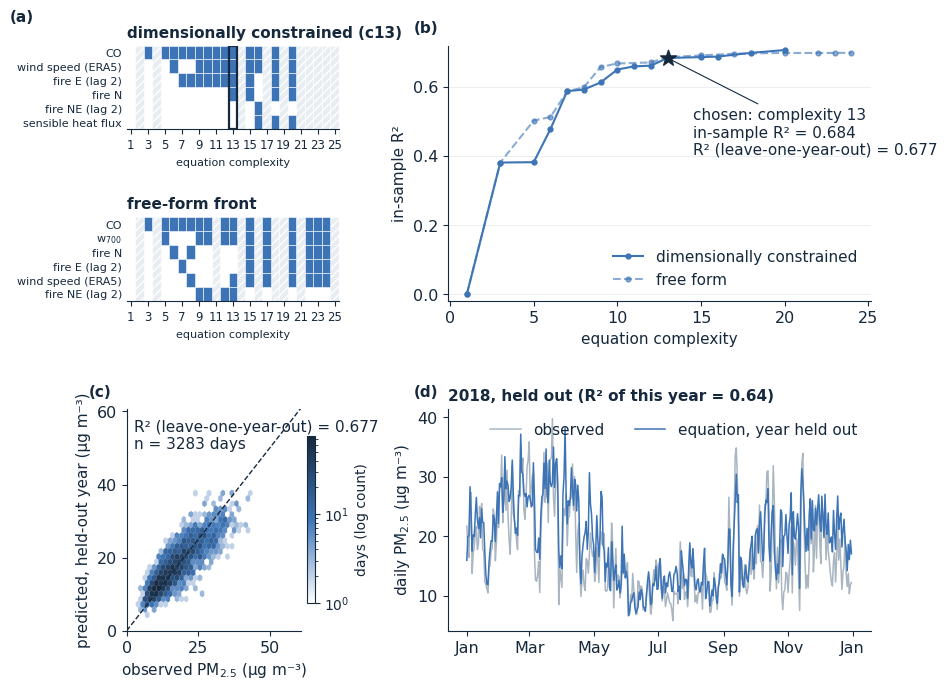

In [5]:
# Fig 3: PM2.5 (blue, not the usual PM25 orange -- see PM25_FIG3_BLUE above)
fig3 = build("pm25", PM25_FIG3_BLUE, "fig03_pm25_lead_equation",
             [("dimensionally constrained (c13)", B/"bogota_pm25_pysr_units_pareto_front.csv", 13),
              ("free-form front", B/"bogota_pysr_pareto_front.csv", None)],
             "bogota_pm25_units", 13, REP_YEAR["pm25"], "µg m⁻³", "PM$_{2.5}$", ("bogota_pm25_freeform", "free form"))

saved /path/to/project/Paper/figures/fig04_o3_lead_equation.png


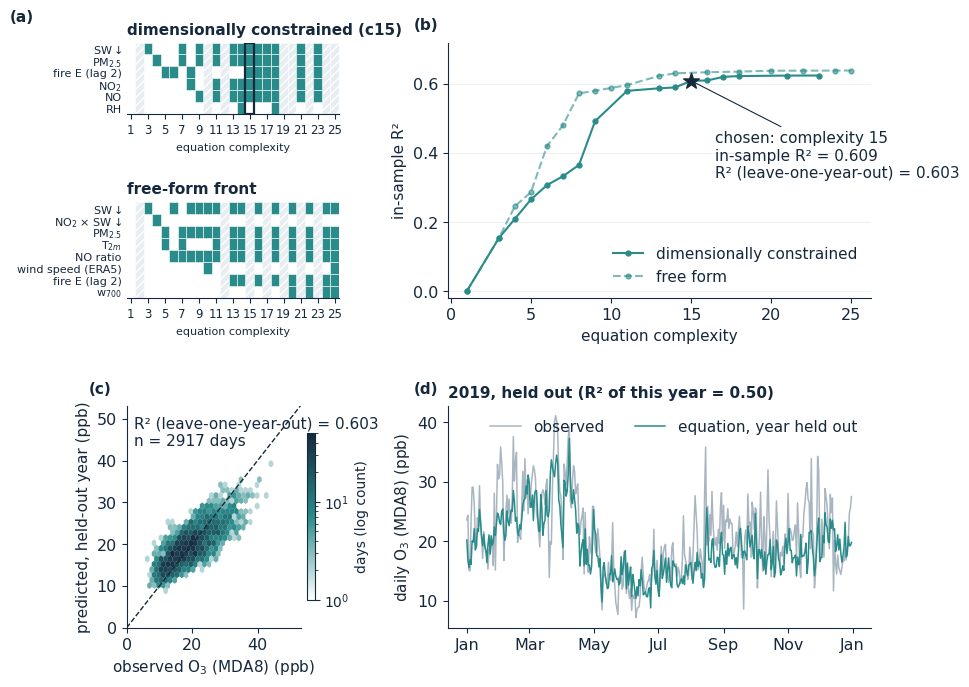

In [6]:
# Fig 4: O3
# 2026-10-06: same pipeline as PM2.5 -- the lead equation comes from the dimensionally constrained front (temperature in
# the pool, photochemical potential split into NO2 and SW; 07_o3_units_with_temp_equation_discovery, seed 1), and the
# free-form front from the same pool is shown underneath. E1 (2026-09-22): Bogotá O3 is ppb, not µg m⁻³ (notebook A4).
fig4 = build("o3", O3, "fig04_o3_lead_equation",
             [("dimensionally constrained (c15)", B/"bogota_o3_pysr_units_fire2_pm_pareto_front_seed0.csv", 15),
              ("free-form front", B/"bogota_o3_temp_pm_falsification_pareto.csv", None)],
             "bogota_o3_units_temp", 15, REP_YEAR["o3"], "ppb", "O$_3$ (MDA8)", ("bogota_o3_falsification_pm", "free form"))